In [2]:
import pandas as pd

Agora que temos os identificadores dos genomas da base do GTDB podemos baixá-los e anotá-los!

# Disclaimer 


A partir deste notebook vamos usar os dados que estão na pasta "dados", o motivo é:
Na elaboração do dataset não foi criado um critério de desempate entre genomas que possuíssem uma pontuação de qualidade igual, ou seja, o mesmo protocolo podia inadvertidamente criar amostras levemente diferentes

Esse erro foi corrigido e, para o nosso caso, não afeta de maneira significativa as próximas etapas, então prosseguimos com os dados já coletados para a disciplina

Reprodutibilidade na ciência é importante! Isso aqui é um leve exemplo dela :)

# Anotação

O que é anotação?

A anotação é o processo no qual identificamos em um genoma quais são os elementos que o compõem. 
Através dela nós conseguimos inferir onde estão:

 - Genes
 - RNAs
 - repetições do CRISPR
 - Outros

Se queremos saber como o nosso genoma se organiza, o primeiro passo é anotar!

Existem várias ferramentas para esse fim e elas vão variar de acordo com o organismo, para esta aula como estamos trabalhando com bactérias escolhemos o programa de anotação Bakta.

Infelizmente, o processo de anotação para 610 genomas é demorado, então nós os anotamos previamente.

Entretanto, a execução do programa é relativamente simples, precisamos fornecer o genoma em formato fasta e baixar a base de dados que o programa usa como referência para nomear os nossos genes. O gargalo é o poder computacional necessário para fazer a anotação em tempo hábil

Entretanto, há recursos online como https://bakta.computational.bio/, que embora impráticos para análise simultânea de vários genomas, auxiliam na anotação

Mesmo diminuindo os nossos genomas alvo a 610, ainda assim é uma quantidade de genomas grande para o tempo que temos em sala de aula, o ideal seria diminuir o número

Queremos ver os genes do 16S nos nossos genomas, vamos ver como eles se distribuem no nosso dataset?

O gene 16S normalmente tem entre 1400 e 1700 pares de base de comprimento, idealmente, queremos algo que esteja dentro dessa faixa

In [3]:
import glob
from pathlib import Path

baktatsvs = pd.read_table('../dados/baktatsv.tsv')

t = pd.read_table('../dados/Selected_genomes.tsv')

In [4]:
rrs = baktatsvs[baktatsvs['assembly'].isin(t['accession'])].query('Gene == "rrs"').assign(length=lambda x: (x.Stop - x.Start).abs() + 1)

In [5]:
print(
    "Genomas com qualquer sinal de 16S:",
    rrs['assembly'].nunique()
)

print(
    "Genomas com 16S na faixa de 1400 a 1700 pares de base:",
    rrs.query('1400 <= length <= 1700')['assembly'].nunique()
)

Genomas com qualquer sinal de 16S: 248
Genomas com 16S na faixa de 1400 a 1700 pares de base: 190


Oh! Surpresa, aparentemente não conseguimos achar 16S em todos, isso está certo?

A detecção pode ser ineficiente, o genoma pode ter erros de montagem, vamos ver a estatística do GTDB?

In [6]:
gtdb_meta = pd.read_table('bac120_metadata.tsv')
gtdb_meta.loc[gtdb_meta['accession'].isin(t['accession'])]['ssu_count'].describe()

count    659.000000
mean       1.254932
std        2.478838
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max       16.000000
Name: ssu_count, dtype: float64

Opa! Efetivamente temos vários exemplares que não possuem  um registro de 16S sequer
Podemos usar isso como filtro, vamos ver como ficou a distribuição taxonômica? Quem que ficou de fora?

<Axes: ylabel='class'>

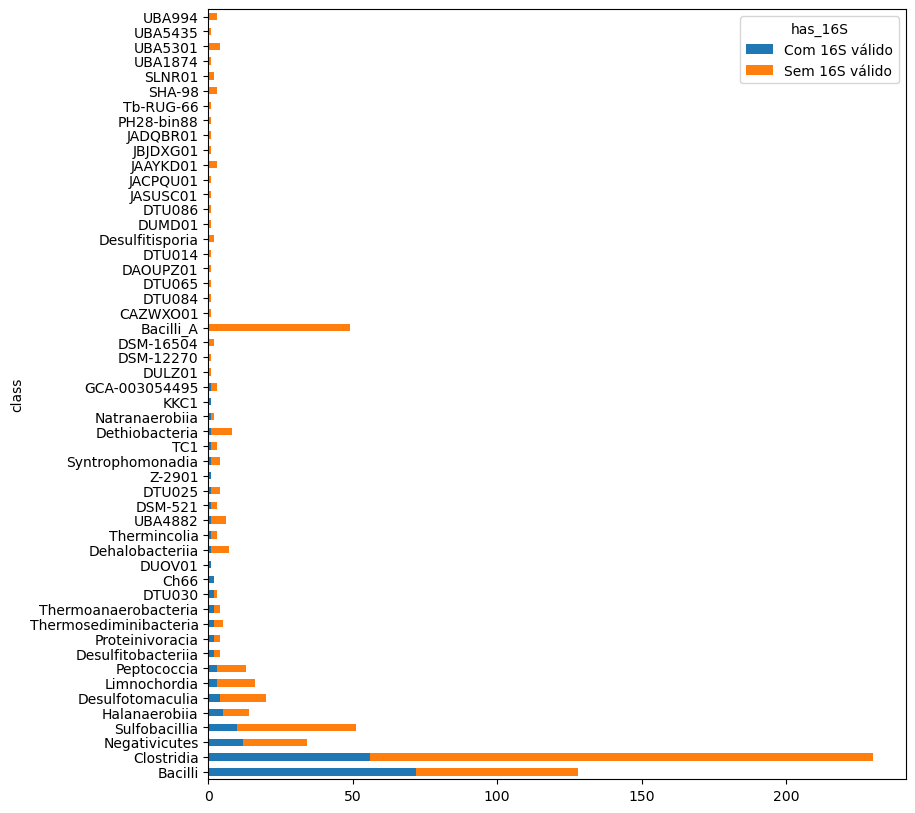

In [7]:
valid = set(
    rrs.query('1400 <= length <= 1700')['assembly']
)

tax_summary = (
    t.assign(has_16S=t.accession.isin(valid))
    .groupby(['class', 'has_16S'])
    .size()
    .unstack(fill_value=0)
    .rename(columns={False: 'Sem 16S válido', True: 'Com 16S válido'})
    .sort_values('Com 16S válido', ascending=False)
)

tax_summary[['Com 16S válido', 'Sem 16S válido']].plot.barh(
    stacked=True,
    figsize=(9, 10)
)

In [8]:
# Melhor cópia válida de 16S por genoma
best = (
    rrs.query('1400 <= length <= 1700')
    .sort_values(['length', 'assembly'], ascending=[False, True])
    .drop_duplicates('assembly')
)

# Genomas selecionados que possuem 16S válido
havers = t.loc[t.accession.isin(best.assembly)].copy()

# Classes presentes na seleção inicial, mas ausentes após o filtro
missing_classes = set(t['class']) - set(havers['class'])

print('Genomas com 16S válido:', len(havers))
print('Classes perdidas:', len(missing_classes))
print(sorted(missing_classes))

Genomas com 16S válido: 190
Classes perdidas: 25
['Bacilli_A', 'CAZWXO01', 'DAOUPZ01', 'DSM-12270', 'DSM-16504', 'DTU014', 'DTU065', 'DTU084', 'DTU086', 'DULZ01', 'DUMD01', 'Desulfitisporia', 'JAAYKD01', 'JACPQU01', 'JADQBR01', 'JASUSC01', 'JBJDXG01', 'PH28-bin88', 'SHA-98', 'SLNR01', 'Tb-RUG-66', 'UBA1874', 'UBA5301', 'UBA5435', 'UBA994']


Vamos tentar recuperar algumas classes que ficaram de fora

In [9]:
# Taxonomia dos genomas do GTDB
tax = gtdb_meta[['accession', 'gtdb_taxonomy']].copy()

ranks = ['domain', 'phylum', 'class', 'order',
         'family', 'genus', 'species']

tax[ranks] = (
    tax.gtdb_taxonomy
    .str.split(';', expand=True)
    .apply(lambda col: col.str.split('__', n=1).str[-1])
)

# Anexar a taxonomia aos metadados
cand = gtdb_meta.merge(
    tax[['accession'] + ranks],
    on='accession',
    how='left'
)

cand['ssu_length'] = pd.to_numeric(
    cand.ssu_length, errors='coerce'
)

# Candidatos com evidência de 16S potencialmente completo
cand = cand.loc[
    cand['class'].isin(missing_classes)
    & (cand.ssu_count > 0)
    & cand.ssu_length.between(1400, 1700)
].copy()

# Score de qualidade
cand['score'] = (
    cand.checkm2_completeness
    - 5 * cand.checkm2_contamination
)

# Seleção determinística
cand = (
    cand.sort_values(
        ['class', 'score', 'accession'],
        ascending=[True, False, True]
    )
    .drop_duplicates('class')
)

display(
    cand[['accession','family', 'class', 'species', 'ncbi_genome_category',
                               'ssu_length', 'checkm2_completeness','score']].reset_index()
)

,index,accession,family,class,species,ncbi_genome_category,ssu_length,checkm2_completeness,score
0,484736,RS_GCF_045444015.1,Metamycoplasmataceae,Bacilli_A,Mycoplasmopsis synoviae,none,1503.0,99.93,99.88
1,414586,RS_GCF_000305935.1,Thermacetogeniaceae,DSM-12270,Thermacetogenium phaeum,none,1536.0,99.98,95.78
2,483589,GB_GCA_001512605.1,DTU014,DTU014,DTU014 sp900016865,derived from metagenome,1531.0,97.35,94.80
3,18674,GB_GCA_050951665.1,DTU065,DTU065,DTU065 sp001512545,derived from metagenome,1535.0,94.18,88.18
4,552018,GB_GCA_050951445.1,DTU086,DTU086,DTU086 sp001513335,derived from metagenome,1519.0,92.74,89.54
5,239129,GB_GCA_050951405.1,DULZ01,DULZ01,JBMNIZ01 sp050951405,derived from metagenome,1569.0,91.12,77.17
6,531790,GB_GCA_963666425.2,JAAYKD01,JAAYKD01,JAJFTT01 sp963666425,derived from metagenome,1516.0,98.49,64.24
7,645097,RS_GCF_035573695.1,JADQBR01,JADQBR01,Metallumcola ferriviriculae,none,1499.0,100.00,87.80
8,554476,GB_GCA_049275475.1,UBA4971,SHA-98,UBA4971 sp900019985,derived from metagenome,1540.0,98.39,98.34
9,460284,GB_GCA_040766585.1,SLNR01,SLNR01,JAXGQE01 sp040766585,derived from metagenome,1544.0,94.68,70.38


### Nota sobre a complementação taxonômica
A amostragem original foi complementada por representantes de linhagens pouco representadas e por organismos da ordem Bacillales. Uma inconsistência na comparação entre categorias taxonômicas afetou parte da seleção dos candidatos. O conjunto resultante foi preservado para manter a correspondência com as análises realizadas para a atividade e é diferente do exibido acima como um exemplo

In [ ]:
#adicionados = pd.read_table('../../to_add.csv')

# Genomas adicionados:

In [50]:
adicionados.iloc[:,0:8]

,index,accession,class,family,species,ssu_length,ncbi_genome_category,gtdb_representative
0,218658,RS_GCF_001584725.1,TC1,TC1,TC1 sp001584725,1572.0,none,t
1,645097,RS_GCF_035573695.1,JADQBR01,JADQBR01,Metallumcola ferriviriculae,1499.0,none,t
2,33009,GB_GCA_050942765.1,UBA4882,UBA4882,UBA4882 sp050942765,1517.0,derived from metagenome,t
3,349554,GB_GCA_050951805.1,DTU025,DTU025,UBA10085 sp012842765,1540.0,derived from metagenome,t
4,209953,GB_GCA_002292025.1,UBA994,UBA994,UBA994 sp002292025,1554.0,derived from metagenome,t
5,239129,GB_GCA_050951405.1,DULZ01,DULZ01,JBMNIZ01 sp050951405,1569.0,derived from metagenome,t
6,460284,GB_GCA_040766585.1,SLNR01,SLNR01,JAXGQE01 sp040766585,1544.0,derived from metagenome,t
7,531790,GB_GCA_963666425.2,JAAYKD01,JAAYKD01,JAJFTT01 sp963666425,1516.0,derived from metagenome,t
8,0,RS_GCF_000007825.1,Bacilli,Bacillaceae_G,Bacillus_A cereus,1550.0,none,t
9,2,RS_GCF_000009045.1,Bacilli,Bacillaceae,Bacillus subtilis,1548.0,none,t


# Outgroup
Para uma árvore, também estamos interessados em termos o que se chama "outgroup", ou seja, organismos que nós sabemos que não pertencem ao grupo taxonômico observado. Aqui pegamos um representante de cada ordem presente em um trabalho de Taib et al 2020

In [18]:
phyla_gtdb = [
    'Coprothermobacterota',
    'Coprothermobacterota',
    'Actinomycetota',
    'Actinomycetota',
    'Bacteroidota',
    'Cyanobacteriota',
    'Cyanobacteriota',
    'Deinococcota',
    'Pseudomonadota',
    'Verrucomicrobiota',   # PVC_Chlamydiae (class Chlamydiia in GTDB)
    'Planctomycetota',
    'Spirochaetota',
]
gtdb_meta = pd.read_table('bac120_metadata.tsv')
gtdb_meta['score'] = gtdb_meta['checkm2_completeness'] - 5*gtdb_meta['checkm2_contamination']
GTDBtax = pd.read_table('bac120_taxonomy.tsv', names=['genome','tax'])
GTDBtax[['domain', 'phylum', 'class', 'order', 'family', 'genus', 'species']] = GTDBtax['tax'].str.split(';', expand=True).apply(lambda col: col.str.replace(r'^[a-z]__', '', regex=True))
og = (gtdb_meta
      .merge(GTDBtax[['genome', 'phylum', 'species']], left_on='accession', right_on='genome')
      .query('phylum in @phyla_gtdb')
      .query('gtdb_representative == "t" and ncbi_genome_category != "derived from metagenome"')
      .query('ncbi_assembly_level == "Complete Genome" and ssu_count > 0')
      .sort_values(['phylum', 'checkm2_completeness'], ascending=[True, False])
      .groupby('phylum').head(2)
      [['accession', 'phylum', 'species', 'score','ssu_length']]).reset_index()

In [20]:
og

,index,accession,phylum,species,score,ssu_length
0,1163,RS_GCF_038405225.1,Actinomycetota,Arthrobacter_B citreus_A,99.65,1526
1,1362,RS_GCF_036013955.1,Actinomycetota,Streptomyces sp036013955,98.85,1525
2,5947,RS_GCF_020386615.1,Bacteroidota,Chitinophaga pendula,98.80,1526
3,6343,RS_GCF_000973105.1,Bacteroidota,Zobellia galactanivorans,99.85,1521
4,876387,RS_GCF_000020945.1,Coprothermobacterota,Coprothermobacter proteolyticus,98.96,1533
5,606575,GB_GCA_026184435.1,Coprothermobacterota,JAADFF01 sp013153035,96.62,1592
6,13773,GB_GCA_000317655.1,Cyanobacteriota,Cyanobacterium stanieri,97.90,1486
7,14367,RS_GCF_000316665.1,Cyanobacteriota,Rivularia sp000316665,94.75,1484
8,5936,RS_GCF_000196275.1,Deinococcota,Deinococcus geothermalis,99.95,1507
9,177969,RS_GCF_000092125.1,Deinococcota,Allomeiothermus silvanus,94.80,1491
